### Installation of numpy, opencv-python, and matplotlib 

In [4]:
%pip install numpy opencv-python matplotlib

Note: you may need to restart the kernel to use updated packages.


### Imports Laibrary

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

OpenCV version: 5.0.0
NumPy version: 2.4.6
Libraries imported successfully!


### Loading The Dgital Image

In [20]:
image_path = "my_image.png"

img = cv.imread(image_path)

if img is None:
    raise FileNotFoundError(
        f"Image not found: {image_path}"
    )

print("Image loaded successfully!")
print("Image shape:", img.shape)
print("Image data type:", img.dtype)

Image loaded successfully!
Image shape: (1024, 1536, 3)
Image data type: uint8


### Inspecting Image (Print the height, width, and number of channels)

In [3]:
height, width, channels = img.shape

print("Image Height:", height)
print("Image Width:", width)
print("Number of Channels:", channels)

Image Height: 1024
Image Width: 1536
Number of Channels: 3


### Inspecting Image (Print the top-left and center pixels using [row, column] indexing.)

In [8]:
print("Top-left pixel (BGR):", img[0, 0])

center_y = height // 2
center_x = width // 2

print("Center coordinates (row, column):",
      (center_y, center_x))

print("Center pixel (BGR):",
      img[center_y, center_x])

Top-left pixel (BGR): [131 117 105]
Center coordinates (row, column): (512, 768)
Center pixel (BGR): [64 50 38]


### Inspecting Image (Print the global minimum/maximum and per-channel minimum/maximum values)

In [9]:
print("Global minimum:", img.min())
print("Global maximum:", img.max())

print("Per-channel minimum (B, G, R):",
      img.min(axis=(0, 1)))

print("Per-channel maximum (B, G, R):",
      img.max(axis=(0, 1)))

Global minimum: 0
Global maximum: 255
Per-channel minimum (B, G, R): [0 0 0]
Per-channel maximum (B, G, R): [255 255 255]


### Color Space Conversion

In [6]:
rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

red = rgb[:, :, 0]
green = rgb[:, :, 1]
blue = rgb[:, :, 2]

print("RGB shape:", rgb.shape)
print("Grayscale shape:", gray.shape)

RGB shape: (1024, 1536, 3)
Grayscale shape: (1024, 1536)


### Extracting Individual Color Channels

In [7]:
red = rgb[:, :, 0]
green = rgb[:, :, 1]
blue = rgb[:, :, 2]

print("Red Channel Shape:", red.shape)
print("Green Channel Shape:", green.shape)
print("Blue Channel Shape:", blue.shape)

Red Channel Shape: (1024, 1536)
Green Channel Shape: (1024, 1536)
Blue Channel Shape: (1024, 1536)


### Visualizing Original Image and Color Channels

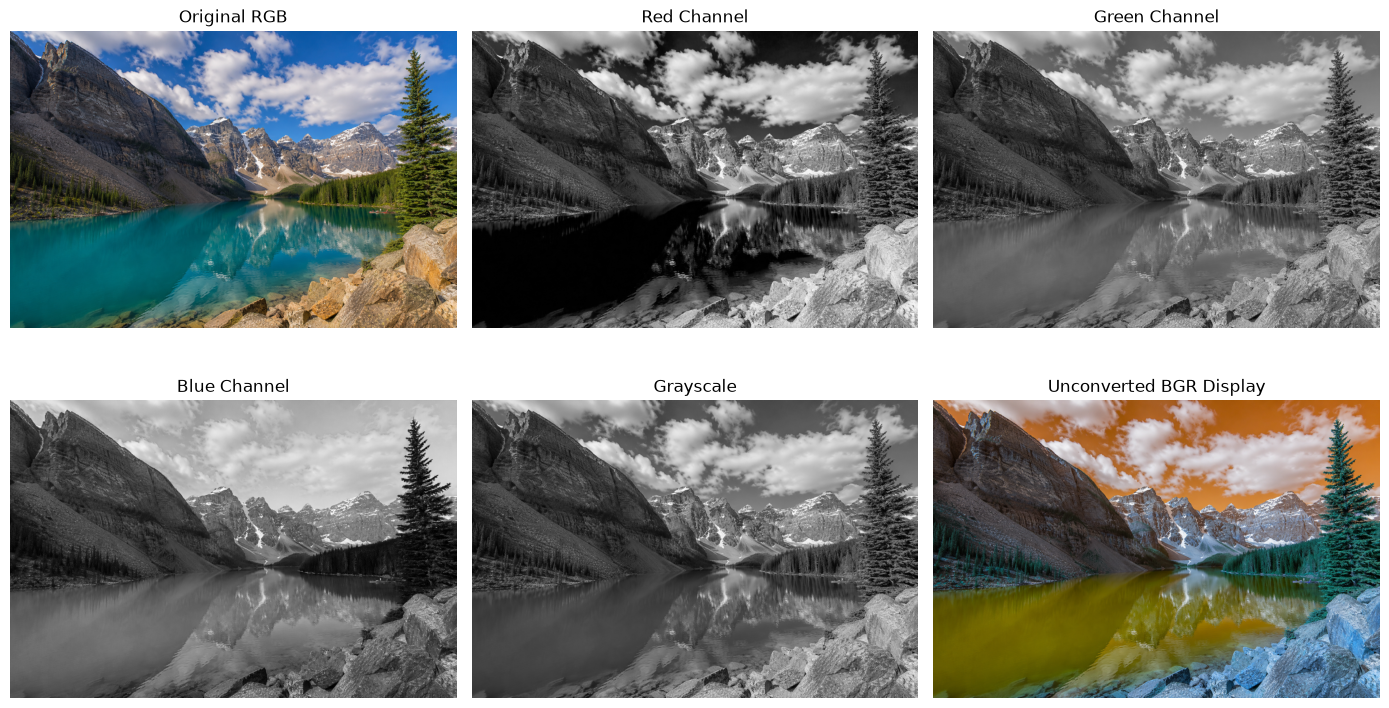

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original RGB")

axes[0, 1].imshow(red, cmap="gray")
axes[0, 1].set_title("Red Channel")

axes[0, 2].imshow(green, cmap="gray")
axes[0, 2].set_title("Green Channel")

axes[1, 0].imshow(blue, cmap="gray")
axes[1, 0].set_title("Blue Channel")

axes[1, 1].imshow(gray, cmap="gray")
axes[1, 1].set_title("Grayscale")

axes[1, 2].imshow(img)
axes[1, 2].set_title("Unconverted BGR Display")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Extracting Center Pixel RGB and HEX Values

In [22]:
height, width, channels = img.shape

center_y = height // 2
center_x = width // 2

print("Center Y:", center_y)
print("Center X:", center_x)

center_rgb = rgb[center_y, center_x]

r, g, b = map(int, center_rgb)

hex_color = f"#{r:02X}{g:02X}{b:02X}"

print("Center pixel RGB:", (r, g, b))
print("Center pixel HEX:", hex_color)

Center Y: 512
Center X: 768
Center pixel RGB: (38, 50, 64)
Center pixel HEX: #263240


### Image Cropping and Resizing

In [13]:
y_start = (height - 100) // 2
x_start = (width - 100) // 2

crop_rgb = rgb[
    y_start:y_start + 100,
    x_start:x_start + 100
]

print("Crop shape:", crop_rgb.shape)

Crop shape: (100, 100, 3)


### Resizing the Cropped Image (200×200)

In [14]:
resized_rgb = cv.resize(
    crop_rgb,
    (200, 200),
    interpolation=cv.INTER_LINEAR
)

print("Resized shape:", resized_rgb.shape)

Resized shape: (200, 200, 3)


### Comparing Original, Cropped, and Resized Images

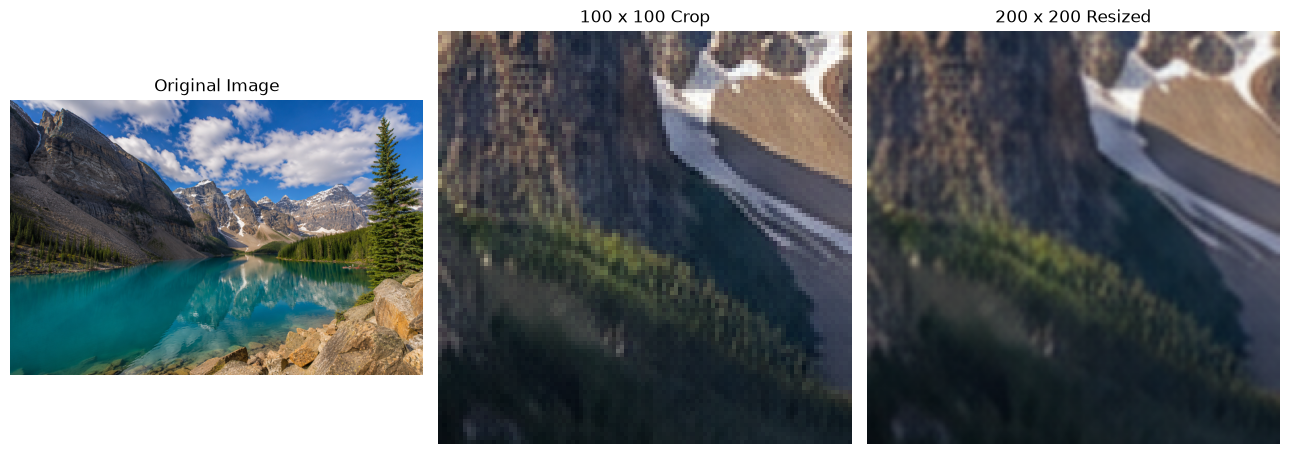

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original Image")

axes[1].imshow(crop_rgb)
axes[1].set_title("100 x 100 Crop")

axes[2].imshow(resized_rgb)
axes[2].set_title("200 x 200 Resized")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Saving the Resized Image

In [16]:
resized_bgr = cv.cvtColor(
    resized_rgb,
    cv.COLOR_RGB2BGR
)

saved = cv.imwrite(
    "resized_crop.png",
    resized_bgr
)

print("Image saved successfully:", saved)

Image saved successfully: True


### Grayscale Histogram

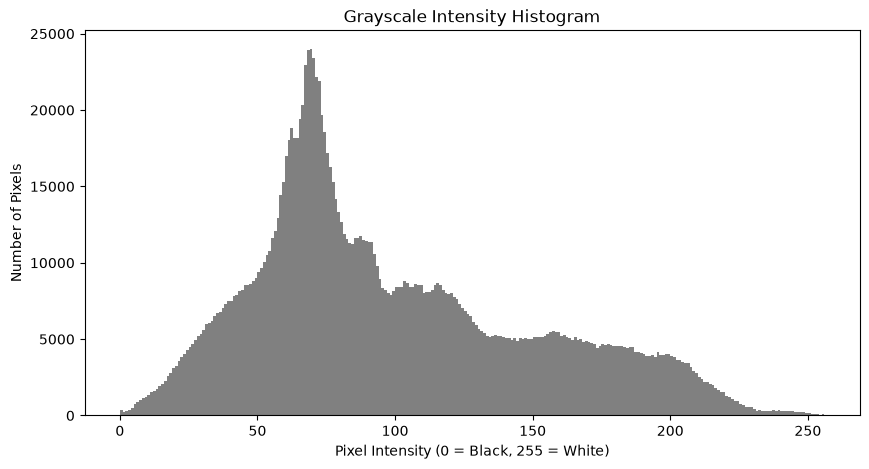

Histogram saved successfully!


In [17]:
gray_flat = gray.flatten()

plt.figure(figsize=(10, 5))

plt.hist(
    gray_flat,
    bins=256,
    range=(0, 256),
    color="gray"
)

plt.title("Grayscale Intensity Histogram")
plt.xlabel("Pixel Intensity (0 = Black, 255 = White)")
plt.ylabel("Number of Pixels")

plt.savefig(
    "grayscale_histogram.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Histogram saved successfully!")

### Bit Depth and Quantization

#### Generating an 8-Bit Grayscale Gradient

In [18]:
gradient = np.arange(256, dtype=np.uint8)

gradient_image = np.tile(gradient, (50, 1))

print("Gradient shape:", gradient_image.shape)
print("Unique values:", len(np.unique(gradient)))

Gradient shape: (50, 256)
Unique values: 256


#### Quantizing Gradients to 1-Bit, 2-Bit, and 4-Bit

In [19]:
def quantize_gradient(gradient, bits):
    levels = 2 ** bits

    quantized = np.round(
        gradient.astype(np.float32)
        * (levels - 1) / 255
    )

    quantized = np.round(
        quantized * 255 / (levels - 1)
    )

    return quantized.astype(np.uint8)


gradient_1bit = quantize_gradient(gradient, 1)
gradient_2bit = quantize_gradient(gradient, 2)
gradient_4bit = quantize_gradient(gradient, 4)

print("8-bit:", len(np.unique(gradient)))
print("1-bit:", len(np.unique(gradient_1bit)))
print("2-bit:", len(np.unique(gradient_2bit)))
print("4-bit:", len(np.unique(gradient_4bit)))

8-bit: 256
1-bit: 2
2-bit: 4
4-bit: 16


#### Visualizing Different Bit-Depth Gradients

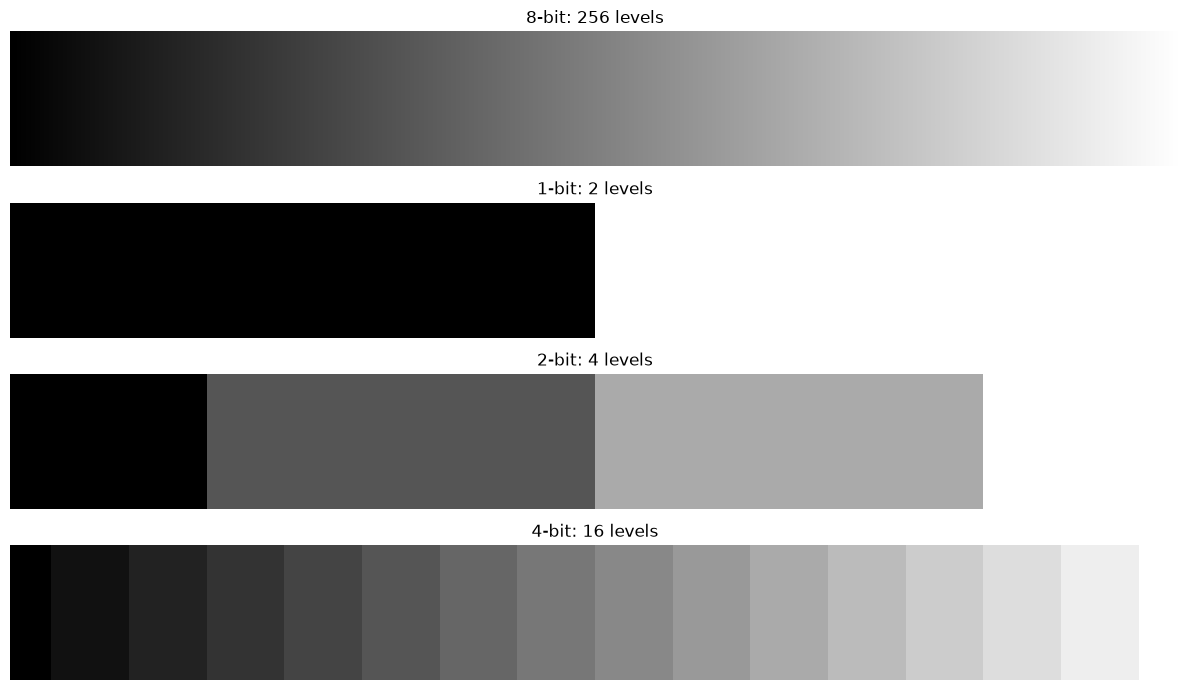

In [20]:
fig, axes = plt.subplots(4, 1, figsize=(12, 7))

gradients = [
    (gradient_image, "8-bit: 256 levels"),
    (np.tile(gradient_1bit, (30, 1)), "1-bit: 2 levels"),
    (np.tile(gradient_2bit, (30, 1)), "2-bit: 4 levels"),
    (np.tile(gradient_4bit, (30, 1)), "4-bit: 16 levels")
]

for ax, (data, title) in zip(axes, gradients):
    ax.imshow(
        data,
        cmap="gray",
        vmin=0,
        vmax=255,
        aspect="auto"
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()